## Ćwiczenie 11: Wstęp do SimpleITK i automatyczna rejestracja obrazów

W tym zeszycie przechodzimy na profesjonalne narzędzie wykorzystywane w obrazowaniu medycznym: **SimpleITK (Insight Toolkit)**.

## 1. Fizyczność obrazu medycznego
W bibliotekach takich jak NumPy czy scikit-image, obraz to tylko macierz pikseli. Współrzędne to indeksy `[y, x]` (np. wiersz 10, kolumna 20).
W SimpleITK obraz reprezentuje fizyczny wycinek przestrzeni. Kluczowe atrybuty to:
* **Size (Rozmiar):** Liczba pikseli/wokseli (jak w NumPy, ale uwaga: SITK używa konwencji `[x, y, z]`, a nie `[z, y, x]`).
* **Spacing (Odstęp/Rozdzielczość):** Fizyczny rozmiar jednego piksela w milimetrach (np. `1.2 mm x 1.2 mm`).
* **Origin (Początek):** Fizyczne współrzędne pierwszego piksela w układzie odniesienia skanera (w mm).
* **Direction (Kierunek):** Macierz cosinusów kierunkowych, określająca jak obraz jest zorientowany w przestrzeni.

In [13]:
!pip install SimpleITK

import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Pobieramy obraz mózgu z skimage i konwertujemy do formatu float32
brain_np = data.brain()[5, :, :].astype(np.float32)
#Normalizacja jasności
brain_np = (brain_np - brain_np.min()) / (brain_np.max() - brain_np.min())

# Tworzymy obiekt obrazu SimpleITK z macierzy NumPy
fixed_image = sitk.GetImageFromArray(brain_np)

# Nadajemy obrazowi atrybuty fizyczne (Symulujemy, że piksel ma 1x1 mm)
fixed_image.SetSpacing((1.0, 1.0))
fixed_image.SetOrigin((0.0, 0.0))

print("--- Atrybuty fizyczne obrazu ---")
print(f"Rozmiar (Size): {fixed_image.GetSize()} pikseli")
print(f"Rozdzielczość (Spacing): {fixed_image.GetSpacing()} mm")
print(f"Początek (Origin): {fixed_image.GetOrigin()} mm")

Defaulting to user installation because normal site-packages is not writeable
--- Atrybuty fizyczne obrazu ---
Rozmiar (Size): (256, 256) pikseli
Rozdzielczość (Spacing): (1.0, 1.0) mm
Początek (Origin): (0.0, 0.0) mm


### 2. Przygotowanie danych: celowe "zepsucie" (przesunięcie) obrazu
Stworzymy teraz drugi skan (`moving_image`), który będzie obrócony i przesunięty względem oryginału. Zadaniem naszego algorytmu będzie zignorowanie faktu, że piksele są w innych miejscach i nałożenie obrazów na siebie w fizycznej przestrzeni.

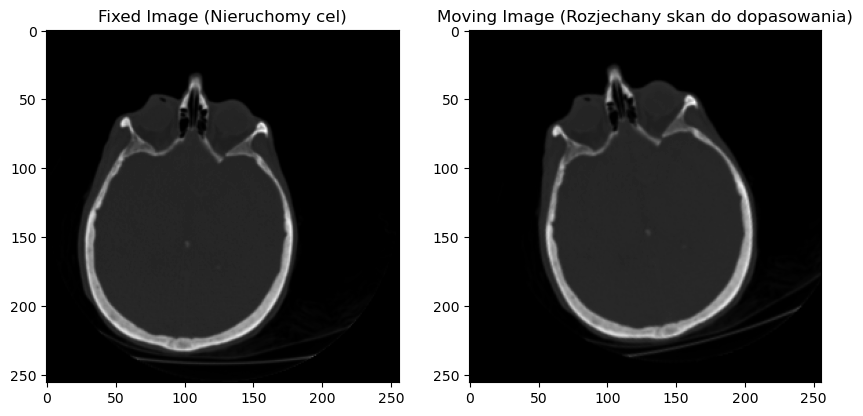

In [16]:
# Definiujemy transformację: Translacja (przesunięcie) i Rotacja (obrót)
# Uwaga: W SITK obrót domyślnie odbywa się wokół punktu (0,0)
synthetic_transform = sitk.Euler2DTransform()
synthetic_transform.SetTranslation((15.0, -20.0))  # Przesunięcie o 15 mm w X i -20 mm w Y
synthetic_transform.SetAngle(np.radians(15))       # Obrót o 15 stopni

# Tworzymy przesunięty obraz używając Resample (Odwrotne mapowanie w praktyce!)
moving_image = sitk.Resample(fixed_image, fixed_image, synthetic_transform, sitk.sitkLinear, 0.0, fixed_image.GetPixelID())

# Wizualizacja
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(sitk.GetArrayFromImage(fixed_image), cmap='gray')
ax[0].set_title('Fixed Image (Nieruchomy cel)')
ax[1].imshow(sitk.GetArrayFromImage(moving_image), cmap='gray')
ax[1].set_title('Moving Image (Rozjechany skan do dopasowania)')
plt.show()

### 3. Automatyczna Rejestracja (budowa pipeline'u)

Uruchamiamy mechanizm poszukiwania optymalnych parametrów transformacji. Proces ten wymaga 4 elementów:
1. **Inicjalizator:** Wstępne nałożenie środków fizycznych obu skanów, aby algorytm miał dobry punkt startowy i wiedział, wokół jakiego punktu obracać (środek głowy, a nie róg skanu).
2. **Metryka:** Sposób mierzenia podobieństwa. Użyjemy `MeanSquares` (Błędu średniokwadratowego), bo oba skany mają tę samą intensywność szarości.
3. **Optymalizator:** Algorytm spadku gradientu, który minimalizuje naszą metrykę.
4. **Interpolacja:** Metoda wyliczania wartości ułamkowych pikseli (tutaj liniowa).

In [19]:
# 1. Przygotowanie obiektu rejestracji
R = sitk.ImageRegistrationMethod()

# 2. Ustawienie Metryki
R.SetMetricAsMeanSquares()

# 3. Ustawienie Optymalizatora (Spadek gradientu o regularnym kroku)
R.SetOptimizerAsRegularStepGradientDescent(learningRate=2.0, minStep=1e-4, numberOfIterations=200)

# 4. Ustawienie Interpolatora
R.SetInterpolator(sitk.sitkLinear)

# 5. WSTĘPNE DOPASOWANIE (Inicjalizacja)
# Dopasowuje geometryczne środki obrazów i ustanawia to jako punkt początkowy i środek obrotu
initial_transform = sitk.CenteredTransformInitializer(
    fixed_image, 
    moving_image, 
    sitk.Euler2DTransform(), 
    sitk.CenteredTransformInitializerFilter.MOMENTS
)
R.SetInitialTransform(initial_transform, inPlace=False)

# URUCHOMIENIE REJESTRACJI
print("Rozpoczynamy rejestrację... (Szukanie optymalnej macierzy)")
final_transform = R.Execute(fixed_image, moving_image)

print("\n--- Wynik Rejestracji ---")
print(f"Optymalizator zakończył pracę z powodem: {R.GetOptimizerStopConditionDescription()}")
print(f"Ostateczna wartość metryki (błąd): {R.GetMetricValue():.4f}")
print(f"Odnalezione parametry transformacji: {final_transform.GetParameters()}")

Rozpoczynamy rejestrację... (Szukanie optymalnej macierzy)

--- Wynik Rejestracji ---
Optymalizator zakończył pracę z powodem: RegularStepGradientDescentOptimizerv4: Maximum number of iterations (200) exceeded.
Ostateczna wartość metryki (błąd): 0.0003
Odnalezione parametry transformacji: (-0.25843609974199344, 26.222225563778167, -8.648153850391225)


### 4. Wizualizacja i weryfikacja wyników
Teraz nakładamy wyliczoną przed chwilą macierz (`final_transform`) na nasz "rozjechany" `moving_image`, aby z powrotem spasować go z `fixed_image`.

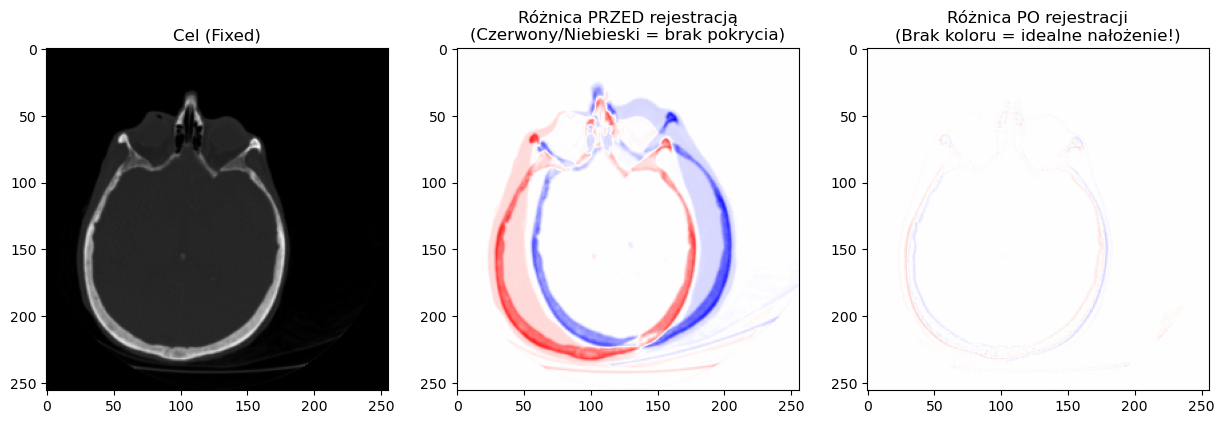

In [22]:
# Przekształcamy Moving Image przy pomocy znalezionej transformacji
registered_image = sitk.Resample(
    moving_image, 
    fixed_image, 
    final_transform, 
    sitk.sitkLinear, 
    0.0, 
    moving_image.GetPixelID()
)

# Wizualizacja przed i po
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# Nakładamy oba obrazy na siebie za pomocą kolorów lub po prostu różnicy
diff_before = sitk.GetArrayFromImage(fixed_image) - sitk.GetArrayFromImage(moving_image)
diff_after = sitk.GetArrayFromImage(fixed_image) - sitk.GetArrayFromImage(registered_image)

ax[0].imshow(sitk.GetArrayFromImage(fixed_image), cmap='gray')
ax[0].set_title('Cel (Fixed)')

ax[1].imshow(diff_before, cmap='bwr', vmin=-1, vmax=1)
ax[1].set_title('Różnica PRZED rejestracją\n(Czerwony/Niebieski = brak pokrycia)')

ax[2].imshow(diff_after, cmap='bwr', vmin=-1, vmax=1)
ax[2].set_title('Różnica PO rejestracji\n(Brak koloru = idealne nałożenie!)')

plt.show()